In [2]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

from tensorflow.keras import layers, models, regularizers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seeds configured.")

Random seeds configured.


In [3]:
from google.colab import drive


drive.mount("/content/drive")
print("Google Drive connected successfully.")

Mounted at /content/drive
Google Drive connected successfully.


In [4]:
PROJECT_DIR = "/content/drive/MyDrive/Nexar_Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "Dataset_2FPS")
POSITIVE_DIR = os.path.join(DATASET_DIR, "positive")
NEGATIVE_DIR = os.path.join(DATASET_DIR, "negative")
MANIFEST_DIR = os.path.join(PROJECT_DIR, "Manifests")
TRAIN_MANIFEST = os.path.join(MANIFEST_DIR, "train_manifest.csv")
VAL_MANIFEST = os.path.join(MANIFEST_DIR, "validation_manifest.csv")
MODEL_DIR = os.path.join(PROJECT_DIR, "Models")

PUBLIC_POSITIVE_DIR = os.path.join(
    PROJECT_DIR,
    "Public_Test",
    "Processed",
    "positive"
)

PUBLIC_NEGATIVE_DIR = os.path.join(
    PROJECT_DIR,
    "Public_Test",
    "Processed",
    "negative"
)

print("Positive files:", len(os.listdir(PUBLIC_POSITIVE_DIR)))
print("Negative files:", len(os.listdir(PUBLIC_NEGATIVE_DIR)))
EXPERIMENT_NAME = "mobilenetv2_bigru_16frames_augmented"
EXPERIMENT_DIR = os.path.join(MODEL_DIR,EXPERIMENT_NAME)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

print("Project paths configured successfully.")

Positive files: 334
Negative files: 333
Project paths configured successfully.


In [5]:
required_paths = {
    "Project": PROJECT_DIR,
    "Positive Dataset": POSITIVE_DIR,
    "Negative Dataset": NEGATIVE_DIR,
    "Train Manifest": TRAIN_MANIFEST,
    "Validation Manifest": VAL_MANIFEST
}

for name, path in required_paths.items():
    exists = os.path.exists(path)
    print(f"{name}: {exists}")
    if not exists:
        raise FileNotFoundError(f"Required path not found: {path}")

Project: True
Positive Dataset: True
Negative Dataset: True
Train Manifest: True
Validation Manifest: True


In [6]:
train_df = pd.read_csv(TRAIN_MANIFEST)
validation_df = pd.read_csv(VAL_MANIFEST)

for df in [train_df, validation_df]:
    if "label" not in df.columns and "target" in df.columns:
        df.rename(columns={"target": "label"}, inplace=True)

    if "file_name" not in df.columns and "id" in df.columns:
        df["file_name"] = df["id"].astype(str)

    if "label" not in df.columns:
        raise ValueError("Missing label column.")

    if "file_name" not in df.columns:
        raise ValueError("Missing file_name column.")

print("Train samples:", len(train_df))
print("Validation samples:", len(validation_df))

print("\nTrain distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(validation_df["label"].value_counts())

Train samples: 1200
Validation samples: 300

Train distribution:
label
1    600
0    600
Name: count, dtype: int64

Validation distribution:
label
0    150
1    150
Name: count, dtype: int64


In [7]:
SEQUENCE_LENGTH = 16
IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CHANNELS = 3
MODEL_IMAGE_SIZE = 160
BATCH_SIZE = 1
AUTOTUNE = tf.data.AUTOTUNE

print("Video configuration completed.")

Video configuration completed.


In [8]:
AUGMENTATION_ENABLED = True
BRIGHTNESS_DELTA = 20.0
CONTRAST_MIN = 0.90
CONTRAST_MAX = 1.10
HORIZONTAL_FLIP_PROBABILITY = 0.50

print("Data augmentation configuration completed.")

Data augmentation configuration completed.


In [9]:
def augment_video(
    frames,
    brightness_delta=20.0,
    contrast_range=(0.90, 1.10),
    force_flip=None,
    return_info=False
):
    frames = np.asarray(frames, dtype=np.float32).copy()

    brightness = np.random.uniform(-brightness_delta, brightness_delta)
    frames += brightness

    contrast = np.random.uniform(
        contrast_range[0],
        contrast_range[1]
    )

    mean = np.mean(frames, axis=(0, 1, 2), keepdims=True)
    frames = (frames - mean) * contrast + mean

    if force_flip is None:
        horizontal_flip = np.random.random() < 0.5
    else:
        horizontal_flip = force_flip

    if horizontal_flip:
        frames = np.flip(frames, axis=2)

    frames = np.clip(frames, 0, 255).astype(np.float32)

    if return_info:
        info = {
            "brightness": float(brightness),
            "contrast": float(contrast),
            "horizontal_flip": bool(horizontal_flip)
        }
        return frames, info

    return frames

In [10]:
def prepare_video(npz_path, sequence_length=SEQUENCE_LENGTH):
    with np.load(npz_path) as data:
        frames = data["frames"]

    total_frames = len(frames)

    if total_frames == 0:
        raise ValueError(f"Empty video: {npz_path}")

    if total_frames >= sequence_length:

        indices = np.linspace(
            0,
            total_frames - 1,
            sequence_length
        ).astype(int)

        selected_frames = frames[indices]
        mask = np.ones(sequence_length, dtype=bool)

    else:

        selected_frames = np.zeros(
            (sequence_length, IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS),
            dtype=np.float32
        )

        selected_frames[:total_frames] = frames
        selected_frames[total_frames:] = frames[-1]
        mask = np.zeros(sequence_length, dtype=bool)
        mask[:total_frames] = True

    return selected_frames.astype(np.float32), mask

In [11]:
def normalize_label(value):

    if isinstance(value, str):
        value = value.strip().lower()

        if value in ["positive", "pos", "1"]:
            return 1.0

        if value in ["negative", "neg", "0"]:
            return 0.0

    value = float(value)

    if value not in [0.0, 1.0]:
        raise ValueError(f"Invalid label: {value}")

    return value


def resolve_npz_path(file_name, label, dataset_type="train"):
    label = normalize_label(label)

    if dataset_type == "train":
        base_dir = (POSITIVE_DIR if label == 1.0 else NEGATIVE_DIR)

    elif dataset_type == "public":
        base_dir = (PUBLIC_POSITIVE_DIR if label == 1.0 else PUBLIC_NEGATIVE_DIR)

    else:
        raise ValueError(
            f"Unknown dataset type: {dataset_type}"
        )

    file_stem = Path(str(file_name)).stem
    npz_path = os.path.join(base_dir, file_stem + ".npz")

    if not os.path.isfile(npz_path):
        raise FileNotFoundError(
            f"NPZ file not found: {npz_path}"
        )

    return npz_path


print("Path and label functions created successfully.")

Path and label functions created successfully.


In [12]:
def data_generator(
    dataframe,
    training=False,
    shuffle=False,
    dataset_type="train"
):
    df = dataframe.copy()

    if shuffle:
        df = df.sample(
            frac=1,
            random_state=np.random.randint(0, 1_000_000)
        ).reset_index(drop=True)

    for _, row in df.iterrows():

        label = normalize_label(row["label"])

        npz_path = resolve_npz_path(
            row["file_name"],
            label,
            dataset_type=dataset_type
        )

        frames, mask = prepare_video(npz_path)

        if training and AUGMENTATION_ENABLED:
            frames = augment_video(frames)

        inputs = {
            "video_input": frames,
            "mask_input": mask
        }

        yield inputs, np.float32(label)


print("Unified data generator created successfully.")

Unified data generator created successfully.


In [13]:
output_signature = (
    {
        "video_input": tf.TensorSpec(
            shape=(SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS),
            dtype=tf.float32
        ),

        "mask_input": tf.TensorSpec(
            shape=(SEQUENCE_LENGTH,),
            dtype=tf.bool
        )
    },

    tf.TensorSpec(shape=(), dtype=tf.float32)
)

print("Output signature created successfully.")

Output signature created successfully.


In [14]:
# Train Dataset
train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(
        train_df,
        training=True,
        shuffle=True,
        dataset_type="train"
    ),
    output_signature=output_signature
)

train_dataset = (
    train_dataset
    .repeat()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# Train Evaluation Dataset
train_eval_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(
        train_df,
        training=False,
        shuffle=False,
        dataset_type="train"
    ),
    output_signature=output_signature
)

train_eval_dataset = (
    train_eval_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE))


# Validation Dataset
validation_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(
        validation_df,
        training=False,
        shuffle=False,
        dataset_type="train"
    ),
    output_signature=output_signature
)

validation_dataset = (
    validation_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE))


# Public Test Dataset
test_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(
        public_df,
        training=False,
        shuffle=False,
        dataset_type="public"
    ),
    output_signature=output_signature
)

test_dataset = (
    test_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE))

print("All datasets created successfully.")

All datasets created successfully.


In [43]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(MODEL_IMAGE_SIZE, MODEL_IMAGE_SIZE, CHANNELS)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully.")
print("Backbone trainable:", base_model.trainable)

MobileNetV2 loaded successfully.
Backbone trainable: False


In [55]:
video_input = layers.Input(
    shape=(SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS),
    name="video_input"
)

mask_input = layers.Input(
    shape=(SEQUENCE_LENGTH,), dtype=tf.bool, name="mask_input")
x = layers.TimeDistributed(
    layers.Resizing(MODEL_IMAGE_SIZE, MODEL_IMAGE_SIZE),
    name="frame_resize"
)(video_input)
x = layers.TimeDistributed(
    layers.Rescaling(scale=1.0 / 127.5, offset=-1.0),
    name="frame_normalization"
)(x)
x = layers.TimeDistributed(base_model, name="feature_extraction")(x)
x = layers.LayerNormalization(name="feature_normalization")(x)
x = layers.Dropout(0.20, name="temporal_input_dropout")(x)
x = layers.Bidirectional(
    layers.GRU(32, dropout=0.20, recurrent_dropout=0.0,return_sequences=False),
    name="bidirectional_gru"
)(x, mask=mask_input)
x = layers.LayerNormalization(name="temporal_normalization")(x)
x = layers.Dropout(0.40, name="gru_dropout")(x)
x = layers.Dense(
    32,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="dense_features"
)(x)
x = layers.LayerNormalization(name="dense_normalization")(x)
x = layers.Dropout(0.40, name="classifier_dropout")(x)
output = layers.Dense(
    1,
    activation="sigmoid",
    dtype="float32",
    name="collision_prediction"
)(x)

model = models.Model(
    inputs={"video_input": video_input, "mask_input": mask_input},
    outputs=output,
    name="MobileNetV2_BiGRU_16Frames_Augmented"
)

model.summary()

Model: "MobileNetV2_BiGRU_16Frames_Augmented"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ video_input         │ (None, 16, 224,   │          0 │ -                 │
│ (InputLayer)        │ 224, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frame_resize        │ (None, 16, 160,   │          0 │ video_input[0][0] │
│ (TimeDistributed)   │ 160, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frame_normalization │ (None, 16, 160,   │          0 │ frame_resize[0][… │
│ (TimeDistributed)   │ 160, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_extraction  │ (None, 16, 1280)  │  2,257,984 │ frame_normalizat… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_normalizat… │ (None, 16, 1280)  │      2,560 │ feature_extracti… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_input_dro… │ (None, 16, 1280)  │          0 │ feature_normaliz… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_input          │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_gru   │ (None, 64)        │    252,288 │ temporal_input_d… │
│ (Bidirectional)     │                   │            │ mask_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_normaliza… │ (None, 64)        │        128 │ bidirectional_gr… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_dropout         │ (None, 64)        │          0 │ temporal_normali… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_features      │ (None, 32)        │      2,080 │ gru_dropout[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_normalization │ (None, 32)        │         64 │ dense_features[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 32)        │          0 │ dense_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ collision_predicti… │ (None, 1)         │         33 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,515,137 (9.59 MB)

 Trainable params: 257,153 (1004.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [56]:
LEARNING_RATE = 1e-4

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [57]:
EPOCHS = 10
BEST_MODEL_PATH = os.path.join(EXPERIMENT_DIR, "best_model.keras")
FINAL_MODEL_PATH = os.path.join(EXPERIMENT_DIR, "final_model.keras")
CSV_LOG_PATH = os.path.join(EXPERIMENT_DIR, "training_history.csv")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(CSV_LOG_PATH)
]

print("Callbacks configured successfully.")

Callbacks configured successfully.


In [58]:
steps_per_epoch = len(train_df)
validation_steps = len(validation_df)

print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))
print("Steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)

Training samples: 1200
Validation samples: 300
Steps per epoch: 1200
Validation steps: 300


In [59]:
history = model.fit(
    train_dataset,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_dataset,
    validation_steps=validation_steps,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - accuracy: 0.5404 - auc: 0.5631 - loss: 0.9300 - precision: 0.5387 - recall: 0.5347
Epoch 1: val_loss improved from None to 0.56633, saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_model.keras
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1051s 810ms/step - accuracy: 0.5650 - auc: 0.6044 - loss: 0.8362 - precision: 0.5679 - recall: 0.5433 - val_accuracy: 0.7067 - val_auc: 0.7962 - val_loss: 0.5663 - val_precision: 0.7768 - val_recall: 0.5800 - learning_rate: 1.0000e-04
Epoch 2/10
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 0s 642ms/step - accuracy: 0.6597 - auc: 0.7153 - loss: 0.6489 - precision: 0.6689 - recall: 0.6606
Epoch 2: val_loss improved from 0.56633 to 0.49596, saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_mo

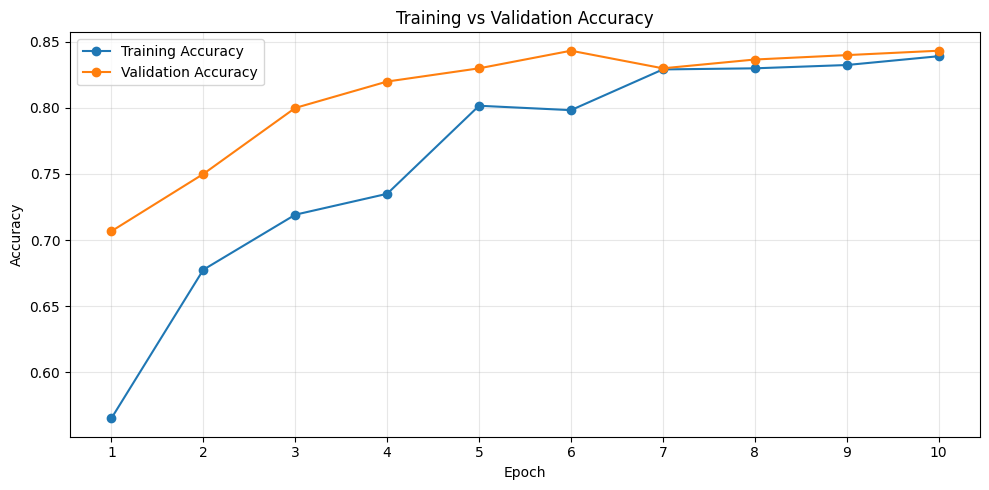

In [61]:
epochs_range = range(
    1,
    len(history.history["loss"]) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

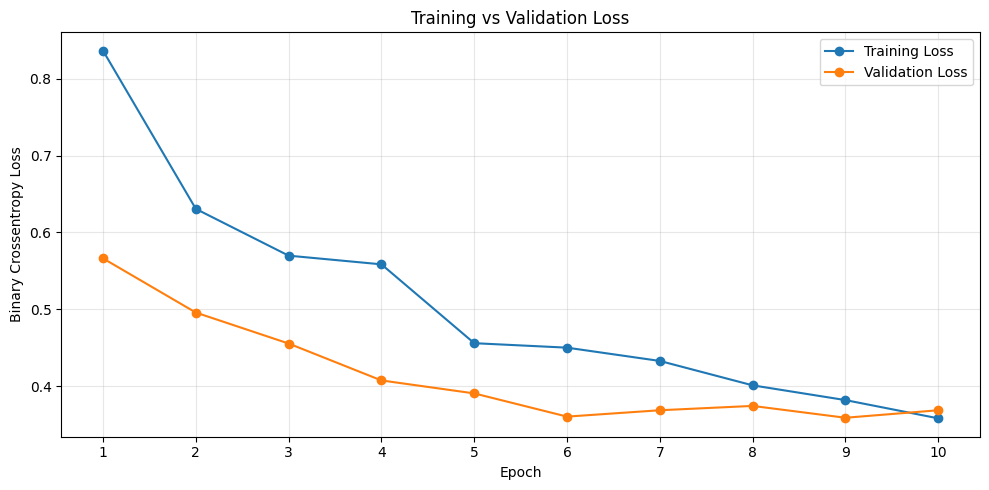

In [62]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
# Define experiment directory
EXPERIMENT_DIR = (
    "/content/drive/MyDrive/Nexar_Project/Models/"
    "mobilenetv2_bigru_16frames_augmented"
)

# Create directory if it does not exist
os.makedirs(EXPERIMENT_DIR, exist_ok=True)

# Define Fine-Tuning output paths
FINE_TUNE_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_finetuned_model.keras"
)

FINE_TUNE_LOG_PATH = os.path.join(
    EXPERIMENT_DIR,
    "finetuning_history.csv"
)

print("Experiment directory:", EXPERIMENT_DIR)
print("Fine-tuned model path:", FINE_TUNE_MODEL_PATH)
print("Fine-tuning log path:", FINE_TUNE_LOG_PATH)

Experiment directory: /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented
Fine-tuned model path: /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_finetuned_model.keras
Fine-tuning log path: /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/finetuning_history.csv


In [ ]:
model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Fine-tuning model compiled successfully.")

In [34]:
FINE_TUNE_EPOCHS = 5

FINE_TUNE_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_finetuned_model.keras"
)

FINE_TUNE_LOG_PATH = os.path.join(
    EXPERIMENT_DIR,
    "finetuning_history.csv"
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=FINE_TUNE_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        FINE_TUNE_LOG_PATH
    )
]

print("Fine-tuning callbacks configured successfully.")

Fine-tuning callbacks configured successfully.


In [46]:
FINE_TUNE_EPOCHS = 5

fine_tune_history = model_ft.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=FINE_TUNE_EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_steps=VALIDATION_STEPS,
    callbacks=fine_tune_callbacks,
    verbose=1
)

Epoch 1/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.8474 - auc: 0.9269 - loss: 0.3432 - precision: 0.8463 - recall: 0.8533
Epoch 1: val_loss improved from None to 0.37369, saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_finetuned_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_finetuned_model.keras
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 582s 485ms/step - accuracy: 0.8550 - auc: 0.9294 - loss: 0.3401 - precision: 0.8458 - recall: 0.8683 - val_accuracy: 0.8300 - val_auc: 0.9286 - val_loss: 0.3737 - val_precision: 0.8667 - val_recall: 0.7800 - learning_rate: 1.0000e-05
Epoch 2/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.8368 - auc: 0.9199 - loss: 0.3644 - precision: 0.8312 - recall: 0.8361
Epoch 2: val_loss improved from 0.37369 to 0.36136, saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_

In [49]:
final_model = tf.keras.models.load_model(
    FINE_TUNE_MODEL_PATH,
    compile=False
)

print("Fine-tuned model loaded successfully!")

Fine-tuned model loaded successfully!


In [51]:
assert os.path.exists(FINE_TUNE_MODEL_PATH), "Fine-tuned model file not found!"
final_model = tf.keras.models.load_model(
    FINE_TUNE_MODEL_PATH,
    compile=False
)

print("Best fine-tuned model loaded successfully.")
print("Model parameters:", f"{final_model.count_params():,}")

Best fine-tuned model loaded successfully.
Model parameters: 2,515,137


In [53]:
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [57]:
validation_results = final_model.evaluate(
    validation_dataset,
    verbose=1,
    return_dict=True
)

print("\nValidation Results:")

for metric, value in validation_results.items():
    print(f"{metric}: {value:.4f}")

300/300 ━━━━━━━━━━━━━━━━━━━━ 46s 154ms/step - accuracy: 0.8433 - auc: 0.9302 - loss: 0.3614 - precision: 0.8705 - recall: 0.8067

Validation Results:
accuracy: 0.8433
auc: 0.9302
loss: 0.3614
precision: 0.8705
recall: 0.8067


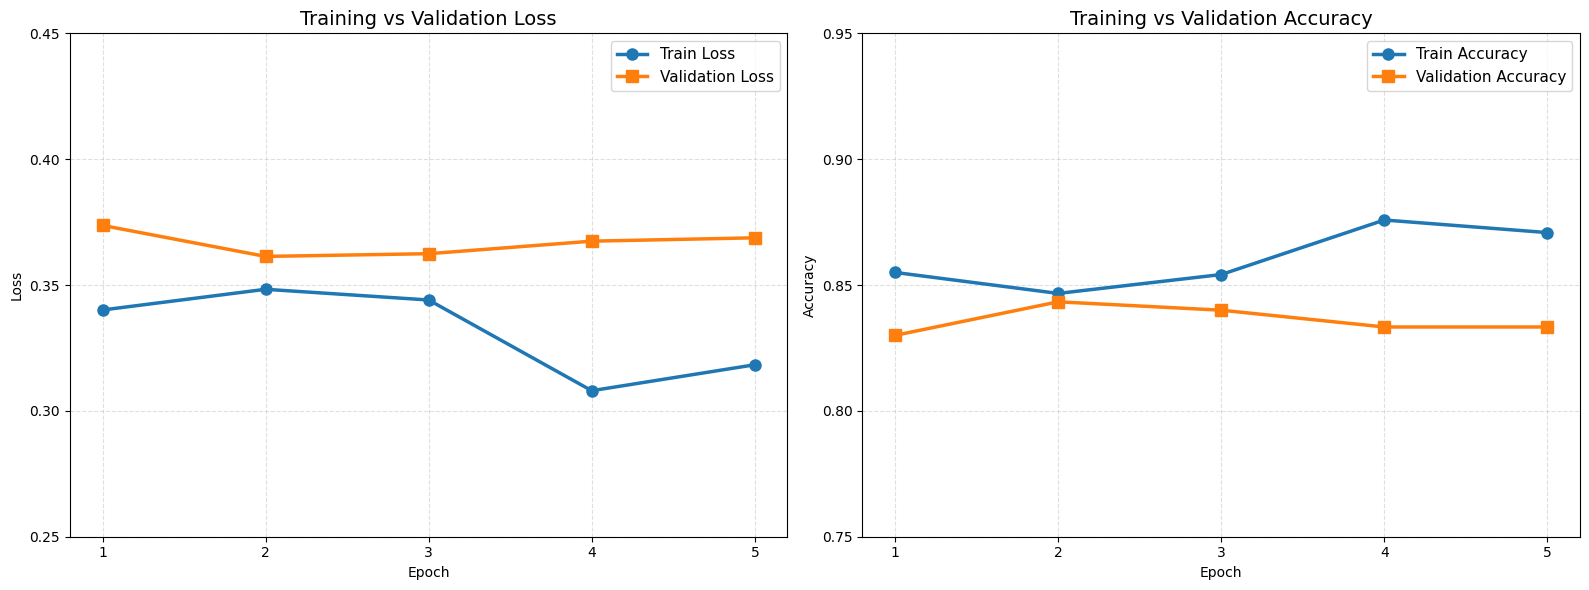

In [63]:
import matplotlib.pyplot as plt
import numpy as np
import math

history = fine_tune_history.history

epochs = np.arange(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]

train_loss = np.array(history["loss"])
val_loss = np.array(history["val_loss"])

ax.plot(
    epochs, train_loss,
    marker="o", markersize=8, linewidth=2.5,
    label="Train Loss"
)

ax.plot(
    epochs, val_loss,
    marker="s", markersize=8, linewidth=2.5,
    label="Validation Loss"
)

loss_min = min(train_loss.min(), val_loss.min())
loss_max = max(train_loss.max(), val_loss.max())

loss_lower = math.floor((loss_min - 0.05) / 0.05) * 0.05
loss_upper = math.ceil((loss_max + 0.05) / 0.05) * 0.05

ax.set_ylim(max(0, loss_lower), loss_upper)
ax.set_yticks(np.arange(max(0, loss_lower), loss_upper + 0.001, 0.05))

ax.set_xlim(0.8, len(epochs) + 0.2)
ax.set_xticks(epochs)
ax.set_title("Training vs Validation Loss", fontsize=14)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)

ax = axes[1]

train_acc = np.array(history["accuracy"])
val_acc = np.array(history["val_accuracy"])

ax.plot(
    epochs, train_acc,
    marker="o", markersize=8, linewidth=2.5,
    label="Train Accuracy"
)

ax.plot(
    epochs, val_acc,
    marker="s", markersize=8, linewidth=2.5,
    label="Validation Accuracy"
)

acc_min = min(train_acc.min(), val_acc.min())
acc_max = max(train_acc.max(), val_acc.max())

acc_lower = math.floor((acc_min - 0.05) / 0.05) * 0.05
acc_upper = math.ceil((acc_max + 0.05) / 0.05) * 0.05

ax.set_ylim(max(0, acc_lower), min(1, acc_upper))
ax.set_yticks(np.arange(max(0, acc_lower), min(1, acc_upper) + 0.001, 0.05))

ax.set_xlim(0.8, len(epochs) + 0.2)
ax.set_xticks(epochs)
ax.set_title("Training vs Validation Accuracy", fontsize=14)
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [37]:

FINE_TUNE_MODEL_PATH = (
    "/content/drive/MyDrive/Nexar_Project/Models/"
    "mobilenetv2_bigru_16frames_augmented/"
    "best_finetuned_model.keras"
)

final_model = tf.keras.models.load_model(
    FINE_TUNE_MODEL_PATH,
    compile=False
)

print("Selected model:", FINE_TUNE_MODEL_PATH)
print("Model name:", final_model.name)
print("Input shapes:", final_model.input_shape)
print("Output shape:", final_model.output_shape)


Selected model: /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_finetuned_model.keras
Model name: MobileNetV2_BiGRU_16Frames_Augmented
Input shapes: [(None, 16), (None, 16, 224, 224, 3)]
Output shape: (None, 1)


In [38]:
import pandas as pd
import os

SOLUTION_PATH = "/content/solution.csv"

assert os.path.exists(SOLUTION_PATH), "solution.csv not found!"

# Keep IDs as strings to preserve leading zeros
solution_df = pd.read_csv(
    SOLUTION_PATH,
    dtype={"id": str}
)

print("Original solution shape:", solution_df.shape)
print("Columns:", solution_df.columns.tolist())

# Validate required columns
required_columns = {"id", "target", "Usage"}

assert required_columns.issubset(solution_df.columns), (
    f"Missing columns: {required_columns - set(solution_df.columns)}"
)

# Select Public samples only
public_df = solution_df[
    solution_df["Usage"].astype(str).str.strip() == "Public"
].copy()

public_df = public_df.reset_index(drop=True)

print("\nPublic Test Set:")
print("Total samples:", len(public_df))
print("\nTarget distribution:")
print(public_df["target"].value_counts(dropna=False))

print("\nFirst 10 samples:")
display(public_df.head(10))

Original solution shape: (1344, 4)
Columns: ['id', 'target', 'Usage', 'group']

Public Test Set:
Total samples: 667

Target distribution:
target
1    334
0    333
Name: count, dtype: int64

First 10 samples:


,id,target,Usage,group
0,00204,1,Public,0
1,00030,1,Public,0
2,00146,1,Public,0
3,00020,1,Public,0
4,00511,1,Public,0
5,00261,1,Public,0
6,00346,1,Public,0
7,00545,1,Public,0
8,00492,1,Public,0
9,00299,1,Public,0


In [39]:
PROJECT_DIR = "/content/drive/MyDrive/Nexar_Project"

MANIFEST_DIR = os.path.join(PROJECT_DIR, "Manifests")
os.makedirs(MANIFEST_DIR, exist_ok=True)

PUBLIC_MANIFEST_PATH = os.path.join(
    MANIFEST_DIR,
    "public_manifest.csv"
)

public_df.to_csv(
    PUBLIC_MANIFEST_PATH,
    index=False
)

print("Public manifest saved successfully.")
print("Path:", PUBLIC_MANIFEST_PATH)

Public manifest saved successfully.
Path: /content/drive/MyDrive/Nexar_Project/Manifests/public_manifest.csv


In [40]:
FINE_TUNE_MODEL_PATH = (
    "/content/drive/MyDrive/Nexar_Project/Models/"
    "mobilenetv2_bigru_16frames_augmented/best_finetuned_model.keras"
)

final_model = tf.keras.models.load_model(
    FINE_TUNE_MODEL_PATH,
    compile=False
)

print("Fine-tuned model loaded successfully.")
print("Model:", FINE_TUNE_MODEL_PATH)

Fine-tuned model loaded successfully.
Model: /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_finetuned_model.keras


In [41]:
public_df = public_df.rename(columns={
    "id": "file_name",
    "target": "label"
})

public_df["file_name"] = public_df["file_name"].astype(str).str.strip()
public_df["label"] = public_df["label"].astype(int)

public_df = public_df.reset_index(drop=True)

print("Public samples:", len(public_df))
print("Columns:", public_df.columns.tolist())

Public samples: 667
Columns: ['file_name', 'label', 'Usage', 'group']


In [27]:
import math

TEST_STEPS = math.ceil(len(public_df) / BATCH_SIZE)

y_pred_prob = final_model.predict(
    test_dataset,
    steps=TEST_STEPS,
    verbose=1
)

y_pred_prob = y_pred_prob.reshape(-1)

y_pred = (y_pred_prob >= 0.5).astype(int)

print("\nPrediction completed.")
print("Total test samples:", len(public_df))
print("Total predictions:", len(y_pred))

667/667 ━━━━━━━━━━━━━━━━━━━━ 577s 822ms/step

Prediction completed.
Total test samples: 667
Total predictions: 667


In [29]:
import numpy as np

y_true = public_df["label"].astype(int).to_numpy()

y_pred_prob = np.asarray(y_pred_prob).reshape(-1)
y_pred = (y_pred_prob >= 0.5).astype(int)

assert len(y_true) == len(y_pred_prob), (
    f"Mismatch: y_true={len(y_true)}, predictions={len(y_pred_prob)}"
)

print("Evaluation data prepared successfully.")
print("Total test samples:", len(y_true))

Evaluation data prepared successfully.
Total test samples: 667


FINAL PUBLIC TEST EVALUATION
Threshold: 0.7000
Accuracy: 0.6597
Precision: 0.6474
Recall: 0.7036
F1-Score: 0.6743
ROC-AUC: 0.7020

Classification Report:
              precision    recall  f1-score   support

    Negative     0.6743    0.6156    0.6436       333
    Positive     0.6474    0.7036    0.6743       334

    accuracy                         0.6597       667
   macro avg     0.6609    0.6596    0.6590       667
weighted avg     0.6608    0.6597    0.6590       667



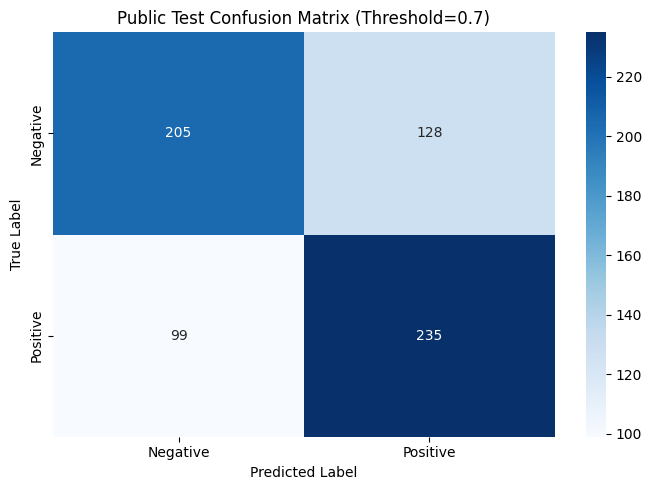


Final evaluation metrics saved successfully.


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Final decision threshold
THRESHOLD = 0.70

# Ground truth and predictions
y_true_final = np.asarray(y_true).astype(int)
y_prob_final = np.asarray(y_pred_prob).reshape(-1)
y_pred_final = (y_prob_final >= THRESHOLD).astype(int)

# Calculate metrics
results = {
    "Threshold": THRESHOLD,
    "Accuracy": accuracy_score(y_true_final, y_pred_final),
    "Precision": precision_score(y_true_final, y_pred_final, zero_division=0),
    "Recall": recall_score(y_true_final, y_pred_final, zero_division=0),
    "F1-Score": f1_score(y_true_final, y_pred_final, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true_final, y_prob_final)
}

print("=" * 55)
print("FINAL PUBLIC TEST EVALUATION")
print("=" * 55)

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_final,
    y_pred_final,
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true_final, y_pred_final)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title(f"Public Test Confusion Matrix (Threshold={THRESHOLD})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Save final metrics
pd.DataFrame([results]).to_csv(
    "/content/drive/MyDrive/Nexar_Project/final_public_metrics.csv",
    index=False
)

print("\nFinal evaluation metrics saved successfully.")
